# Finetuning de Stable Diffusion con LoRA: ilustraciones de libros antiguos

Entrega final del módulo de Modelos de Generación de Imagen.

Finetuning de `CompVis/stable-diffusion-v1-4` con LoRA usando el dataset [gigant/oldbookillustrations](https://huggingface.co/datasets/gigant/oldbookillustrations). Solo usamos las columnas `1600px` (imagen) e `info_alt` (descripción).

Entrenado en un MacBook (GPU de Apple, MPS), por eso usamos un subconjunto del dataset y pocas épocas.

# 0. Instalación de librerías

In [ ]:
# En Colab descomenta la siguiente línea
# !pip install -qq diffusers transformers datasets accelerate peft matplotlib
# !pip uninstall -qq -y torchao   # Colab trae una versión de torchao incompatible con peft

In [1]:
import os, time, random, shutil
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # por si alguna operación no existe en MPS

import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from datasets import load_dataset
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import StableDiffusionPipeline, DDPMScheduler, UNet2DConditionModel, AutoencoderKL
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Dispositivo:", device)

def empty_cache():
    if device == "cuda": torch.cuda.empty_cache()
    elif device == "mps": torch.mps.empty_cache()

/Users/dani/Documents/Master/IA_Pontia/Generacion_Imagenes_Tarea/entrega/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1027 19:30:21.747000 19686 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Dispositivo: mps


# 1. Configuración e hiperparámetros

Parámetros que vamos a ir cambiando respecto al notebook de clase.

In [18]:
pretrained_model_name = "CompVis/stable-diffusion-v1-4"
dataset_name = "gigant/oldbookillustrations"
image_column, caption_column = "1600px", "info_alt"

# --- Entrenamiento ---
resolution = 512
n_train_images = 200   # el dataset tiene 4154 imagenes, usamos solo un subconjunto
num_epochs = 2
batch_size = 1              # no cabe mas en memoria
grad_accum_steps = 2        # batch efectivo = 2
learning_rate = 2e-4
lora_rank = 16              # en clase usamos 6
lora_alpha = 16
seed = 42

# --- Generación ---
num_inference_steps = 20
guidance_scale = 7.5
prompts = [
    "A sailing ship in the middle of a stormy sea",
    "An old man with a long beard reading a book by candlelight",
    "A castle on top of a hill surrounded by trees",
    "A woman walking in a garden with her dog",
    "A lion resting under a tree",
]

# --- Rutas de salida ---
out_dir = os.path.abspath(".")
dir_antes, dir_despues = f"{out_dir}/imagenes/antes", f"{out_dir}/imagenes/despues"
dir_lora, dir_modelo = f"{out_dir}/lora_weights", f"{out_dir}/modelo_final"
for d in (dir_antes, dir_despues): os.makedirs(d, exist_ok=True)

# --- Hugging Face ---
HF_REPO_ID = "DaniDRL/lorapontia"
SUBIR_A_HF = True

def seed_everything(s):
    random.seed(s); torch.manual_seed(s)
seed_everything(seed)

def generate(pipe, tag_dir):
    # mismo prompt + misma semilla = misma imagen
    images = []
    for i, p in enumerate(prompts):
        g = torch.Generator("cpu").manual_seed(seed + i)
        img = pipe(p, num_inference_steps=num_inference_steps, guidance_scale=guidance_scale, generator=g).images[0]
        img.save(f"{tag_dir}/{i+1}.png")
        images.append(img)
    return images

# 2. Comportamiento original del modelo pre-entrenado (ANTES)

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 16.03it/s]


5 imágenes 'antes' generadas en 72s


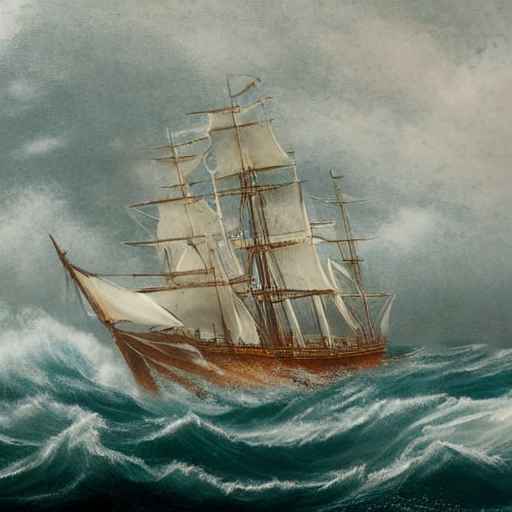

In [3]:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name, safety_checker=None, requires_safety_checker=False
).to(device)
pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)

t0 = time.time()
imgs_antes = generate(pipe, dir_antes)
print(f"{len(imgs_antes)} imágenes 'antes' generadas en {time.time()-t0:.0f}s")
imgs_antes[0]

# 3. Cargamos el dataset para finetunear

Las imágenes no son cuadradas y la altura varía. Reescalamos el lado corto a 512 y recortamos el centro, así no se deforman.

In [ ]:
dataset = load_dataset(dataset_name, split="train")
print(f"Dataset completo: {len(dataset)} imágenes")

# Nos quedamos con las dos columnas que usamos y un subconjunto aleatorio:
dataset = dataset.select_columns([image_column, caption_column])
dataset = dataset.shuffle(seed=seed).select(range(n_train_images))
print(f"Usamos {len(dataset)} imágenes. Ejemplo de tamaño: {dataset[0][image_column].size}")
print("Descripción:", dataset[0][caption_column])

Dataset completo: 4154 imágenes
Usamos 200 imágenes. Ejemplo de tamaño: (1121, 1600)
Descripción: They were changed into swans


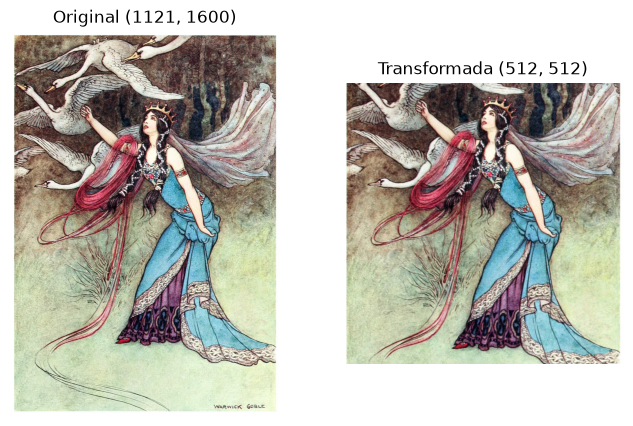

In [6]:
image_transforms = transforms.Compose([
    transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BILINEAR),  # lado corto a 512
    transforms.CenterCrop(resolution),                                                   # recorte cuadrado
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

# Probamos la transformacion con una imagen:
original = dataset[0][image_column].convert("RGB")
transformed = transforms.ToPILImage()(image_transforms(original) * 0.5 + 0.5)
fig, ax = plt.subplots(1, 2, figsize=(8, 5))
ax[0].imshow(original); ax[0].set_title(f"Original {original.size}")
ax[1].imshow(transformed); ax[1].set_title(f"Transformada {transformed.size}")
for a in ax: a.axis("off")
plt.show()

# 4. Cargamos las componentes del modelo por separado

In [7]:
# Vaciamos la memoria antes de cargar las componentes:
del pipe, imgs_antes
import gc; gc.collect(); empty_cache()

tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder").to(device)
vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet").to(device)

# Congelamos VAE, Text Encoder y UNet (la LoRA añade sus propios pesos entrenables):
for m in (vae, text_encoder, unet):
    m.requires_grad_(False)
vae.eval(); text_encoder.eval()

/Users/dani/Documents/Master/IA_Pontia/Generacion_Imagenes_Tarea/entrega/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Loading weights: 100%|██████████| 196/196 [00:00<00:00, 5868.25it/s]


CLIPTextModel(
  (embeddings): CLIPTextEmbeddings(
    (token_embedding): Embedding(49408, 768)
    (position_embedding): Embedding(77, 768)
  )
  (encoder): CLIPEncoder(
    (layers): ModuleList(
      (0-11): 12 x CLIPEncoderLayer(
        (self_attn): CLIPAttention(
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (out_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): CLIPMLP(
          (activation_fn): QuickGELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out_features=768, bias=True)
        )
        (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      )
    )
  )
  (fina

In [8]:
class Text2ImageDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        image = image_transforms(example[image_column].convert("RGB"))
        token = tokenizer(example[caption_column], padding="max_length", truncation=True,
                          max_length=tokenizer.model_max_length, return_tensors="pt")
        return {"pixel_values": image, "input_ids": token.input_ids.squeeze(0)}

train_dataloader = DataLoader(Text2ImageDataset(dataset), batch_size=batch_size, shuffle=True)
print(f"{len(train_dataloader)} batches por época")

200 batches por época


# 5. Añadimos la LoRA y preparamos el entrenamiento

Igual que en clase: LoRA en las capas de atención de la UNet. Además activamos *gradient checkpointing* para ahorrar memoria.

In [9]:
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet.add_adapter(lora_config, adapter_name="oldbooks")
unet.enable_gradient_checkpointing()

lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parámetros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")

optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

Parámetros entrenables (LoRA): 3,188,736 de 862,709,700 (0.37%)


# 6. Entrenamiento

Mismo bucle que en clase. Solo se actualizan los pesos de la LoRA.

Epoch 1: 100%|██████████| 200/200 [05:35<00:00,  1.68s/it, loss=0.3876]

Entrenamiento terminado en 13.4 min


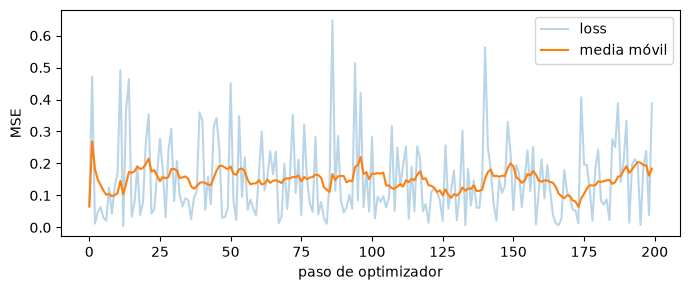

In [10]:
unet.train()
losses, step_losses = [], []
t0 = time.time()

for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch}")
    for step, batch in enumerate(progress_bar):
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(device)).latent_dist.sample() * 0.18215
            encoder_hidden_states = text_encoder(batch["input_ids"].to(device))[0]

        noise = torch.randn_like(latents)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=device).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        (loss / grad_accum_steps).backward()
        step_losses.append(loss.item())

        if (step + 1) % grad_accum_steps == 0:
            optimizer.step()
            optimizer.zero_grad()
            losses.append(sum(step_losses[-grad_accum_steps:]) / grad_accum_steps)
            progress_bar.set_postfix(loss=f"{losses[-1]:.4f}")

print(f"Entrenamiento terminado en {(time.time()-t0)/60:.1f} min")

# Curva de pérdida
w = max(1, len(losses) // 20)
smooth = [sum(losses[max(0, i-w):i+1]) / len(losses[max(0, i-w):i+1]) for i in range(len(losses))]
plt.figure(figsize=(7, 3)); plt.plot(losses, alpha=0.3, label="loss"); plt.plot(smooth, label="media móvil")
plt.xlabel("paso de optimizador"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/imagenes/curva_loss.png", dpi=120); plt.show()

# 7. Guardamos la LoRA y el modelo completo

Guardamos la LoRA sola (`lora_weights/`) y el modelo completo con la LoRA fusionada (`modelo_final/`, en fp16 para que ocupe menos).

In [11]:
unet_lora_state_dict = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet, adapter_name="oldbooks"))
StableDiffusionPipeline.save_lora_weights(save_directory=dir_lora, unet_lora_layers=unet_lora_state_dict)
print("LoRA guardada en", dir_lora, os.listdir(dir_lora))

# Liberamos el entrenamiento
del unet, vae, text_encoder, optimizer, lora_params, train_dataloader
gc.collect(); empty_cache()

pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name, safety_checker=None, requires_safety_checker=False
)
pipe.load_lora_weights(dir_lora)
pipe.fuse_lora()
pipe.unload_lora_weights()
pipe.to(torch.float16)
if os.path.exists(dir_modelo): shutil.rmtree(dir_modelo)
pipe.save_pretrained(dir_modelo)
print("Modelo completo guardado en", dir_modelo)
del pipe; gc.collect(); empty_cache()

LoRA guardada en /Users/dani/Documents/Master/IA_Pontia/Generacion_Imagenes_Tarea/entrega/lora_weights ['pytorch_lora_weights.safetensors']


Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 20.60it/s]
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  8.36it/s]


Modelo completo guardado en /Users/dani/Documents/Master/IA_Pontia/Generacion_Imagenes_Tarea/entrega/modelo_final


# 8. Generamos las mismas imágenes con el modelo finetuneado (DESPUÉS)

Mismos prompts y mismas semillas que antes.

/Users/dani/Documents/Master/IA_Pontia/Generacion_Imagenes_Tarea/entrega/.venv/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 19.50it/s]


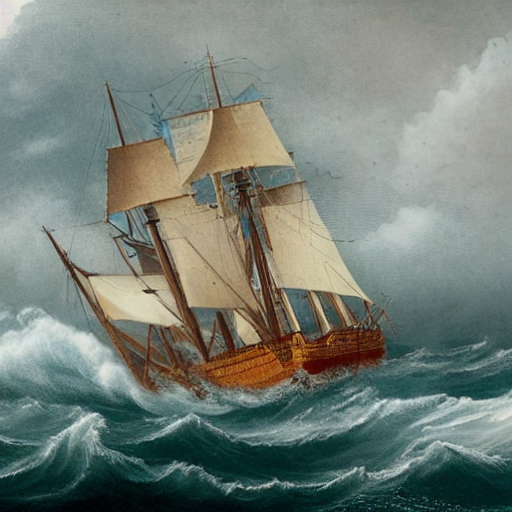

In [12]:
pipe = StableDiffusionPipeline.from_pretrained(dir_modelo, torch_dtype=torch.float16).to(device)
pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)
imgs_despues = generate(pipe, dir_despues)
imgs_despues[0]

## Comparación antes / después

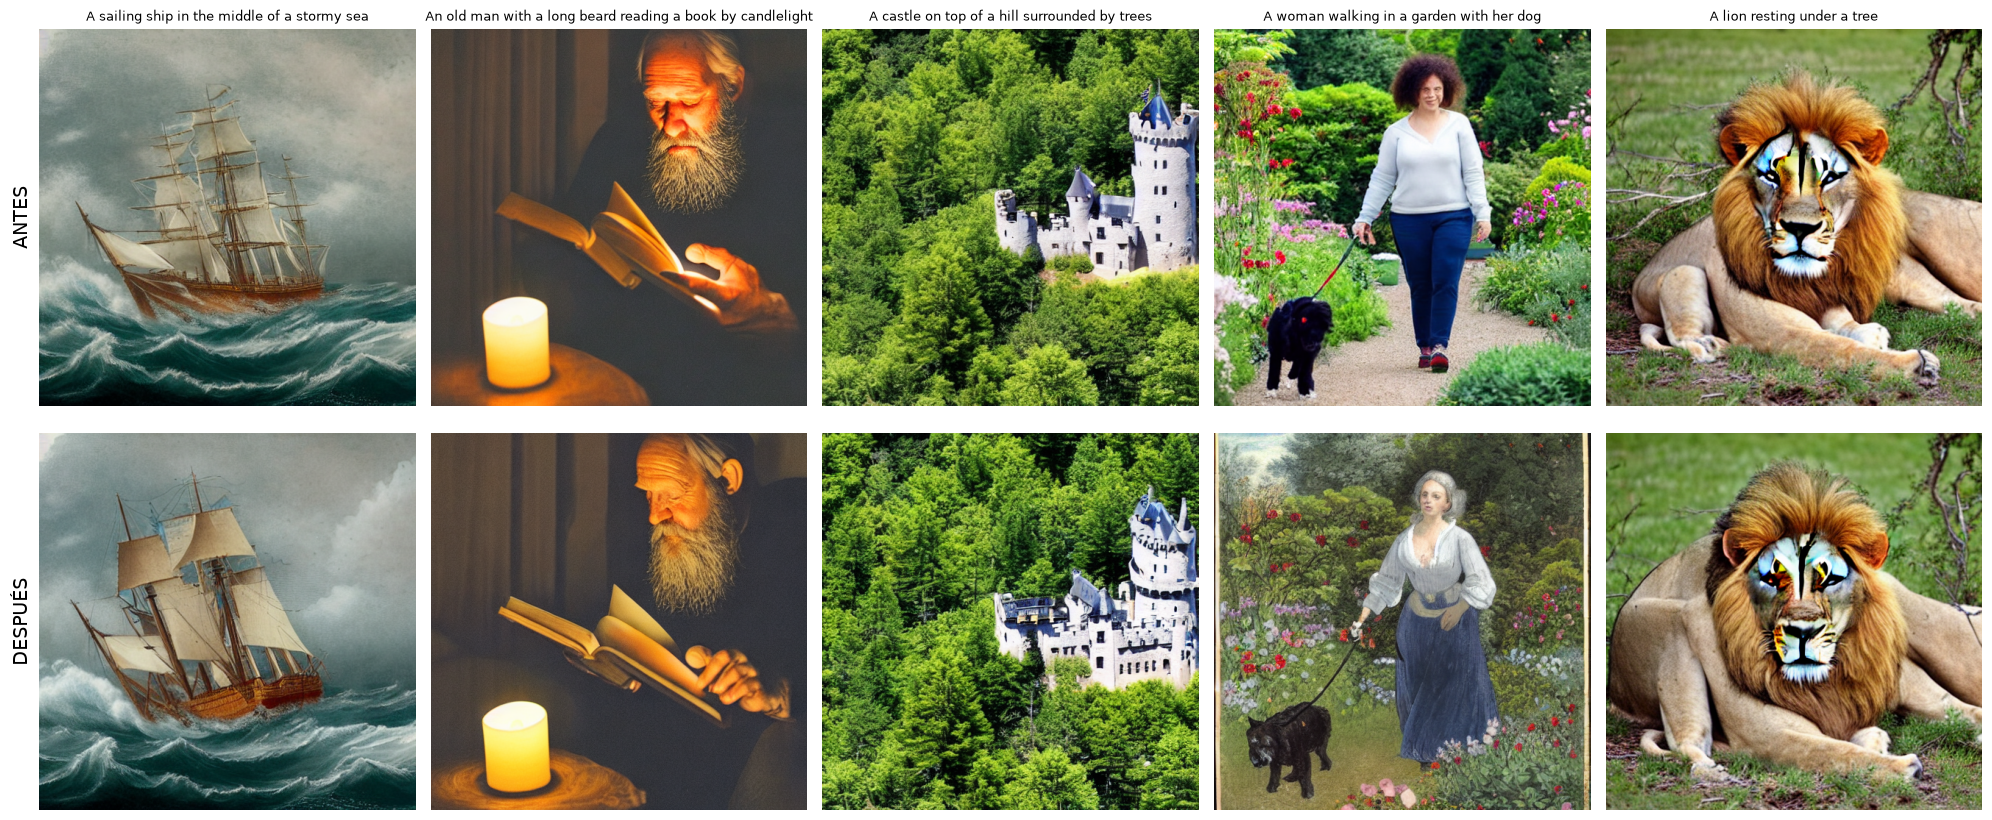

In [13]:
imgs_antes = [Image.open(f"{dir_antes}/{i+1}.png") for i in range(len(prompts))]
imgs_despues = [Image.open(f"{dir_despues}/{i+1}.png") for i in range(len(prompts))]

fig, axes = plt.subplots(2, len(prompts), figsize=(4 * len(prompts), 8.6))
for i, p in enumerate(prompts):
    axes[0, i].imshow(imgs_antes[i]); axes[1, i].imshow(imgs_despues[i])
    axes[0, i].set_title(p, fontsize=9, wrap=True)
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].text(-0.02, 0.5, "ANTES", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center", fontsize=14)
axes[1, 0].text(-0.02, 0.5, "DESPUÉS", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center", fontsize=14)
plt.tight_layout()
plt.savefig(f"{out_dir}/imagenes/comparacion_antes_despues.png", dpi=110)
plt.show()

# 9. Subir el modelo a Hugging Face

Subimos el modelo completo y la LoRA (carpeta `lora/`) a nuestro repo. Hace falta un token de escritura de Hugging Face.

In [19]:
if SUBIR_A_HF:
    from huggingface_hub import HfApi, login
    login()
    api = HfApi()
    api.create_repo(HF_REPO_ID, exist_ok=True)
    api.upload_folder(folder_path=dir_modelo, repo_id=HF_REPO_ID)
    api.upload_folder(folder_path=dir_lora, repo_id=HF_REPO_ID, path_in_repo="lora")
    print(f"Subido: https://huggingface.co/{HF_REPO_ID}")
else:
    print("SUBIR_A_HF=False: no se sube nada todavía.")

Subido: https://huggingface.co/DaniDRL/lorapontia


# 10. Cargar el modelo desde Hugging Face y usarlo con un prompt

100%|██████████| 20/20 [00:11<00:00,  1.80it/s]


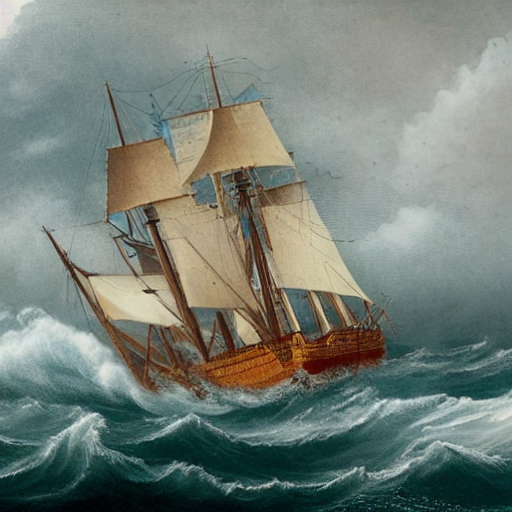

In [20]:
if SUBIR_A_HF:
    pipe_hf = StableDiffusionPipeline.from_pretrained(HF_REPO_ID, torch_dtype=torch.float16).to(device)
    pipe_hf.enable_attention_slicing()
    g = torch.Generator("cpu").manual_seed(seed)
    display(pipe_hf("A sailing ship in the middle of a stormy sea", num_inference_steps=num_inference_steps, generator=g).images[0])
else:
    print("Disponible tras subir el modelo (SUBIR_A_HF=True).")

100%|██████████| 20/20 [00:12<00:00,  1.66it/s]


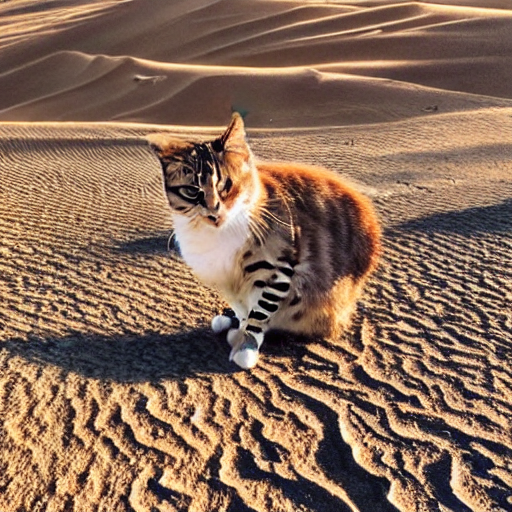

In [23]:
display(pipe_hf("A cat in the middle of the desert in a sunny day", num_inference_steps=num_inference_steps, generator=g).images[0])

100%|██████████| 20/20 [00:12<00:00,  1.63it/s]


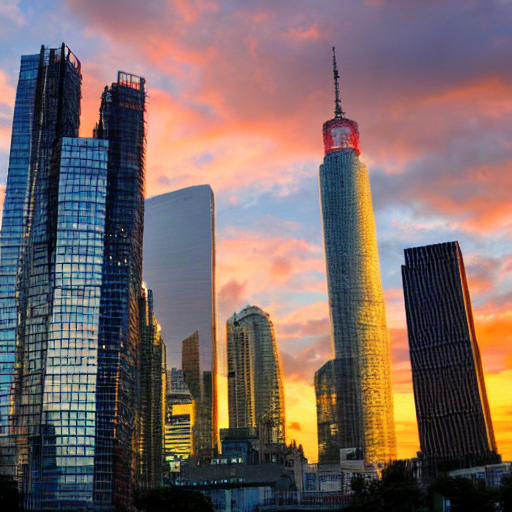

In [24]:
display(pipe_hf("Sunset in a city with skycrappers", num_inference_steps=num_inference_steps, generator=g).images[0])